# Systemy AI – Laboratorium 7
## Zadanie: klasyfikator softmax w PyTorch – pingwiny

Napisz samodzielnie w PyTorch klasyfikator softmax, który rozpoznaje **gatunek pingwina** (Adelie, Chinstrap, Gentoo) na podstawie **dwóch** cech: długości i wysokości dzioba. Znasz te dane z Lab 4 – tym razem nie używasz gotowego `fit`, tylko sam(a) piszesz pętlę uczenia. Wzoruj się na notatniku `SystemyAI_Lab7_wzor.ipynb`.

Dwie cechy wybraliśmy celowo: wynik da się narysować na płaszczyźnie, a zadanie nie jest trywialne (Adelie i Chinstrap częściowo na siebie nachodzą).

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane → tensory
1. Wczytaj `sns.load_dataset("penguins")`, zostaw wiersze bez braków w `bill_length_mm`, `bill_depth_mm`, `species`.
2. Zamień gatunki na liczby: `gatunki = ["Adelie", "Chinstrap", "Gentoo"]` → 0, 1, 2.
3. Podział **trzyczęściowy** (dwa razy `train_test_split`, `stratify`, `random_state=42`): najpierw 20% na test, potem z reszty 25% na walidację. Wyjdzie 204 / 69 / 69.
4. `StandardScaler` dopasowany **tylko** na train; przekształć wszystkie trzy zbiory.
5. Tensory: `X_tr`, `X_va`, `X_te` (`float32`) oraz `y_tr`, `y_va`, `y_te` (`long`).

Zbiór walidacyjny posłuży do krzywych uczenia i wyboru learning rate, testowy – raz, na końcu.

In [ ]:
# Twoje rozwiązanie
import seaborn as sns
import torch
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Wczytanie danych i usunięcie braków w kluczowych kolumnach
penguins = sns.load_dataset("penguins")
penguins = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm", "species"])

# 2. Mapowanie klas tekstowych na indeksy numeryczne
gatunki = ["Adelie", "Chinstrap", "Gentoo"]
penguins = penguins[penguins["species"].isin(gatunki)]
X = penguins[["bill_length_mm", "bill_depth_mm"]].values
y = penguins["species"].map({"Adelie": 0, "Chinstrap": 1, "Gentoo": 2}).values

# 3. Trzyczęściowy podział z zachowaniem proporcji klas (stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

# 4. Standaryzacja dopasowana wyłącznie do zbioru treningowego
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# 5. Konwersja do tensorów PyTorch
X_tr = torch.tensor(X_train, dtype=torch.float32)
y_tr = torch.tensor(y_train, dtype=torch.long)
X_va = torch.tensor(X_val, dtype=torch.float32)
y_va = torch.tensor(y_val, dtype=torch.long)
X_te = torch.tensor(X_test, dtype=torch.float32)
y_te = torch.tensor(y_test, dtype=torch.long)

In [ ]:
# TEST
assert X_tr.shape == (204, 2) and X_va.shape == (69, 2) and X_te.shape == (69, 2)
assert X_tr.dtype == torch.float32 and y_tr.dtype == torch.long
assert set(y_tr.tolist()) == {0, 1, 2}
assert torch.allclose(X_tr.mean(dim=0), torch.zeros(2), atol=1e-5), "Standaryzacja dopasowana na train"
print("1 OK")

1 OK


---
## 2. Model i strata przed uczeniem
1. `torch.manual_seed(0)`, potem `model = nn.Linear(2, 3)` i `loss_fn = nn.CrossEntropyLoss()`.
2. Policz `loss0` – stratę na zbiorze treningowym **przed** uczeniem (`.item()`).
3. Policz `p0` – prawdopodobieństwa (softmax) dla pierwszych 3 pingwinów treningowych i wypisz je.

In [ ]:
# Twoje rozwiązanie
import torch.nn as nn

# 1. Ustawienie ziarna generatora losowego i inicjalizacja struktur
torch.manual_seed(0)
model = nn.Linear(2, 3)
loss_fn = nn.CrossEntropyLoss()

# 2. Obliczenie straty początkowej przed procesem uczenia
logits0 = model(X_tr)
loss0 = loss_fn(logits0, y_tr).item()

# 3. Obliczenie prawdopodobieństw klas (softmax) dla pierwszych 3 próbek
p0 = torch.softmax(model(X_tr[:3]), dim=1)

print(f"Strata przed rozpoczęciem uczenia (loss0): {loss0:.4f}")
print("\nPrawdopodobieństwa klas dla pierwszych trzech pingwinów:")
for i, prob in enumerate(p0):
  print(f"Pingwin {i+1}: Adelie: {prob[0]:.4f}, Chinstrap: {prob[1]:.4f}, Gentoo: {prob[2]:.4f}")

Strata przed rozpoczęciem uczenia (loss0): 1.5298

Prawdopodobieństwa klas dla pierwszych trzech pingwinów:
Pingwin 1: Adelie: 0.1938, Chinstrap: 0.5522, Gentoo: 0.2539
Pingwin 2: Adelie: 0.3298, Chinstrap: 0.3845, Gentoo: 0.2857
Pingwin 3: Adelie: 0.4144, Chinstrap: 0.2371, Gentoo: 0.3485


In [ ]:
# TEST
assert 0.8 < loss0 < 2.0
assert torch.allclose(p0.sum(dim=1), torch.ones(3))
print("2 OK")

2 OK


*Twoja odpowiedź:* model, który dla każdego pingwina daje wszystkim trzem gatunkom prawdopodobieństwo 1/3, ma stratę dokładnie ln 3 ≈ 1.10. Dlaczego? Czy twoja `loss0` jest blisko tej wartości?
loss0 nie jest bliskie tej wartości. strata 1.1 wynika z wzoru na obliczanie mse
$$\text{MSE}(w, b) = \frac{1}{n}\sum_i (\hat{y}_i - y_i)^2$$




---
## 3. Pętla uczenia
Napisz funkcję `train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va)`, która:
- ustawia `torch.manual_seed(seed)` i tworzy **nowy** `nn.Linear(2, 3)`, `CrossEntropyLoss` i `optim.SGD(..., lr=lr)`,
- uczy model mini-batchami (`DataLoader` z `shuffle=True`) przez `epochs` epok,
- po każdej epoce zapisuje w słowniku `historia` trzy listy: `"train loss"` (na `X`), `"val loss"` i `"val acc"` (na `X_val`); parametry `X` i `X_val` przydadzą się w punkcie 5,
- zwraca `(model, historia)`.

Uruchom ją dla `lr=0.1` (`model_01, hist_01`) i narysuj dwa wykresy: straty train/val oraz accuracy val w funkcji epoki.

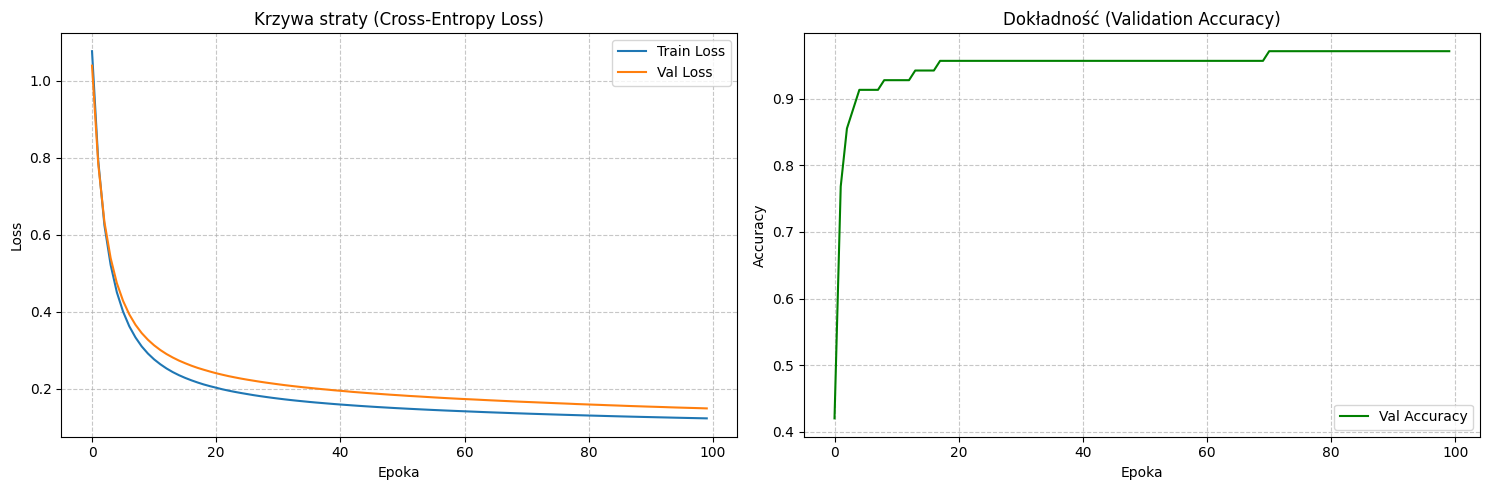

In [ ]:
# Twoje rozwiązanie
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

def train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
  # 1. Gwarancja powtarzalności obliczeń i inicjalizacja komponentów
  torch.manual_seed(seed)
  model_local = torch.nn.Linear(2, 3)
  loss_fn_local = torch.nn.CrossEntropyLoss()
  optimizer = optim.SGD(model_local.parameters(), lr=lr)

  dataset = TensorDataset(X, y_tr)
  dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

  historia = {"train loss": [], "val loss": [], "val acc": []}

  # 2. Główna pętla ucząca
  for epoch in range(epochs):
    model_local.train()
    for X_batch, y_batch in dataloader:
      optimizer.zero_grad()
      loss = loss_fn_local(model_local(X_batch), y_batch)
      loss.backward()
      optimizer.step()

    # Ewaluacja po zakończeniu epoki
    model_local.eval()
    with torch.no_grad():
      train_loss = loss_fn_local(model_local(X), y_tr).item()
      val_outputs = model_local(X_val)
      val_loss = loss_fn_local(val_outputs, y_va).item()
      val_acc = (val_outputs.argmax(dim=1) == y_va).float().mean().item()

      historia["train loss"].append(train_loss)
      historia["val loss"].append(val_loss)
      historia["val acc"].append(val_acc)

  return model_local, historia

# Uruchomienie uczenia dla lr=0.1
model_01, hist_01 = train(0.1)

# 3. Wizualizacja krzywych uczenia
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Wykres funkcji straty
ax1.plot(hist_01["train loss"], label="Train Loss")
ax1.plot(hist_01["val loss"], label="Val Loss")
ax1.set_title("Krzywa straty (Cross-Entropy Loss)")
ax1.set_xlabel("Epoka")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.7)

# Wykres dokładności (accuracy) na walidacji
ax2.plot(hist_01["val acc"], label="Val Accuracy", color="green")
ax2.set_title("Dokładność (Validation Accuracy)")
ax2.set_xlabel("Epoka")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
# TEST
assert set(hist_01) == {"train loss", "val loss", "val acc"} and len(hist_01["val acc"]) == 100
assert hist_01["train loss"][-1] < hist_01["train loss"][0], "Strata powinna maleć"
assert hist_01["val acc"][-1] > 0.9
print("3 OK")

3 OK


---
## 4. Learning rate
Naucz model dla `lr` ∈ {0.001, 0.01, 0.1, 1.0}. Na jednym wykresie narysuj krzywe **straty treningowej** dla wszystkich czterech wartości, a wyniki końcowe (`val loss`, `val acc` po 100 epokach) zbierz w `pd.DataFrame` o nazwie `wyniki_lr` (indeks: wartości lr).

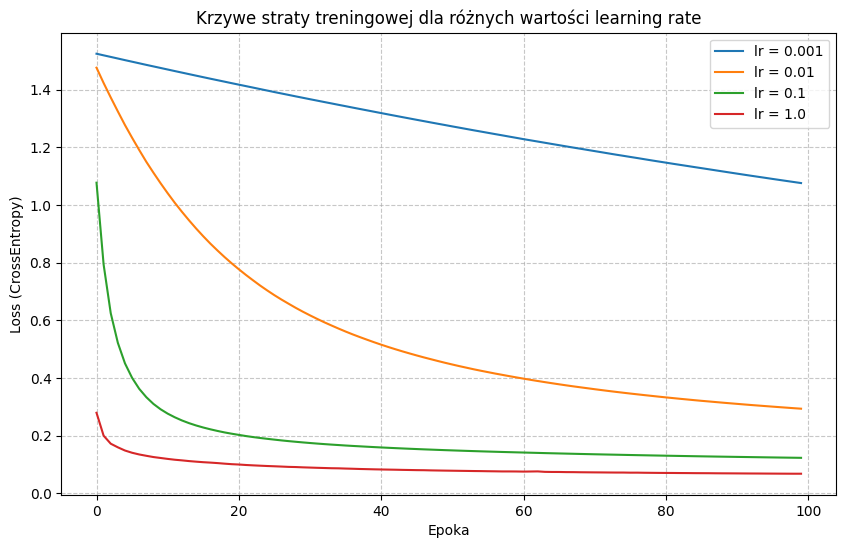

,val loss,val acc
0.001,1.038211,0.420290
0.010,0.329397,0.927536
0.100,0.149183,0.971014
1.000,0.072390,0.971014


In [ ]:
# Twoje rozwiązanie
import pandas as pd
import matplotlib.pyplot as plt

lr_values = [0.001, 0.01, 0.1, 1.0]
historia_lr = {}

# Trenowanie modeli dla różnych wartości learning rate
for lr in lr_values:
  _, historia = train(lr)
  historia_lr[lr] = historia

# Rysowanie krzywych straty treningowej
plt.figure(figsize=(10, 6))
for lr in lr_values:
  plt.plot(historia_lr[lr]["train loss"], label=f"lr = {lr}")

plt.title("Krzywe straty treningowej dla różnych wartości learning rate")
plt.xlabel("Epoka")
plt.ylabel("Loss (CrossEntropy)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

# Zebranie wyników końcowych w DataFrame
dane_lr = {}
for lr, hist in historia_lr.items():
  dane_lr[lr] = {
      "val loss": hist["val loss"][-1],
      "val acc": hist["val acc"][-1]
  }

wyniki_lr = pd.DataFrame.from_dict(dane_lr, orient="index")
display(wyniki_lr)

In [ ]:
# TEST
assert list(wyniki_lr.index) == [0.001, 0.01, 0.1, 1.0]
assert wyniki_lr.loc[0.001, "val loss"] > wyniki_lr.loc[0.1, "val loss"]
print("4 OK")

4 OK


*Twoja odpowiedź:* co widać dla lr = 0.001? Który learning rate wybierasz i na podstawie którego zbioru?
dla lr = 0.001 widoczny jest bardzo wolny spadek straty treningowej dla zbioru walidacyjnego wybieram lr = 0.1 ze względu na szybki spadek val loss oraz wysokie acc


---
## 5. Co daje standaryzacja?
Utwórz `X_tr_raw` i `X_va_raw` – tensory **bez** standaryzacji (surowe milimetry z `X_train`, `X_val`) i naucz model z `lr=0.1`: `train(0.1, X=X_tr_raw, X_val=X_va_raw)`. Porównaj końcową stratę i accuracy z wynikiem z punktu 3. Wynik zapisz w `hist_raw`.

In [ ]:
# Twoje rozwiązanie
# Pobieramy oryginalne, surowe cechy (nieprzetworzone przez StandardScaler)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train_raw, X_val_raw, y_train_raw, y_val_raw = train_test_split(X_train_raw, y_train_raw, test_size=0.25, random_state=42, stratify=y_train_raw)

X_tr_raw = torch.tensor(X_train_raw, dtype=torch.float32)
X_va_raw = torch.tensor(X_val_raw, dtype=torch.float32)

# Trenujemy model na surowych danych przy lr=0.1
model_raw, hist_raw = train(0.1, X=X_tr_raw, X_val=X_va_raw)

# Porównanie wyników z punktu 3 (dane standaryzowane, lr=0.1)
print("Porównanie wyników po 100 epokach (lr=0.1):")
print(f"Dane standaryzowane -> Val Loss: {hist_01['val loss'][-1]:.4f}, Val Acc: {hist_01['val acc'][-1]:.4f}")
print(f"Dane surowe (raw)     -> Val Loss: {hist_raw['val loss'][-1]:.4f}, Val Acc: {hist_raw['val acc'][-1]:.4f}")

Porównanie wyników po 100 epokach (lr=0.1):
Dane standaryzowane -> Val Loss: 0.1492, Val Acc: 0.9710
Dane surowe (raw)     -> Val Loss: 1.6196, Val Acc: 0.9420


In [ ]:
# TEST
assert hist_raw["val acc"][-1] < hist_01["val acc"][-1]
print("5 OK")

5 OK


*Twoja odpowiedź:* dlaczego bez standaryzacji uczenie idzie tak źle, choć model i dane są te same?
brak standaryzacji sprawia że model uznaje dane z większymi nominalnymi wartościami za ważniejsze. docelowy dołek funkcji staje się wąski a reszta funkcji niesymetryczna przez co algorytm ma trudności z odnalezieniem minimum i wpada w oscylacje.

---
## 6. Ocena końcowa i porównanie ze scikit-learn
1. Wybierz model z punktu 4 (wybór na podstawie walidacji) i zapisz go jako `model_koncowy`. Policz `acc_test` – accuracy na **teście**.
2. Naucz `LogisticRegression()` ze scikit-learn na tych samych wystandaryzowanych danych treningowych i policz jej accuracy na teście: `acc_sk`.
3. Wypisz prawdopodobieństwa (softmax) Twojego modelu dla pierwszych 5 pingwinów testowych, z nazwami gatunków i prawdziwym gatunkiem.
4. Narysuj obszary decyzyjne `model_koncowy` na płaszczyźnie (wystandaryzowane cechy) z punktami treningowymi – możesz skopiować funkcję `granica` z wzoru.

Accuracy na zbiorze testowym: 0.9275
Accuracy na zbiorze testowym (scikit-learn): 0.9275
Predykcje dla pierwszych 5 pingwinów testowych:
Pingwin 1: Adelie: 0.9119, Chinstrap: 0.0847, Gentoo: 0.0034 | Prawdziwy gatunek: Adelie
Pingwin 2: Adelie: 0.9602, Chinstrap: 0.0309, Gentoo: 0.0089 | Prawdziwy gatunek: Adelie
Pingwin 3: Adelie: 0.0026, Chinstrap: 0.0240, Gentoo: 0.9734 | Prawdziwy gatunek: Gentoo
Pingwin 4: Adelie: 0.0468, Chinstrap: 0.0896, Gentoo: 0.8636 | Prawdziwy gatunek: Gentoo
Pingwin 5: Adelie: 0.2572, Chinstrap: 0.6798, Gentoo: 0.0630 | Prawdziwy gatunek: Chinstrap


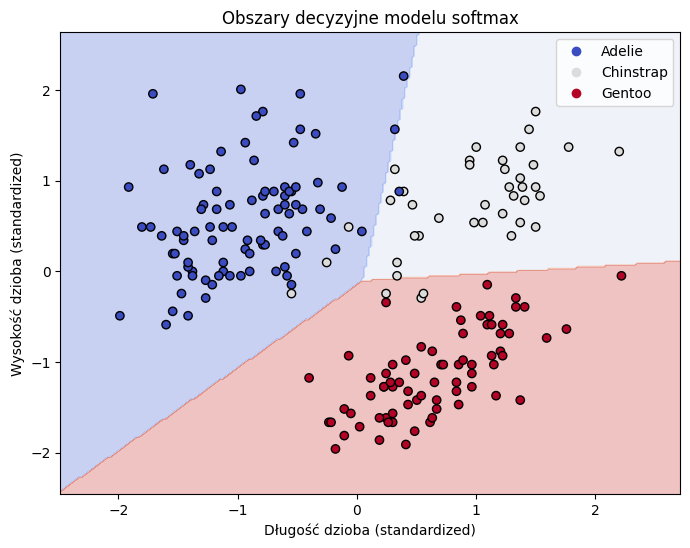

In [ ]:
# Twoje rozwiązanie
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression

# 1. Wybór modelu (wybieramy lr=0.1 na podstawie tabeli wyniki_lr)
model_koncowy, _ = train(0.1)
model_koncowy.eval()
with torch.no_grad():
  test_preds = model_koncowy(X_te)
  acc_test = (test_preds.argmax(dim=1) == y_te).float().mean().item()
print(f"Accuracy na zbiorze testowym: {acc_test:.4f}")

# 2. Logistic Regression ze scikit-learn
sk_model = LogisticRegression()
sk_model.fit(X_train, y_train)
acc_sk = sk_model.score(X_test, y_test)
print(f"Accuracy na zbiorze testowym (scikit-learn): {acc_sk:.4f}")

# 3. Wypisanie prawdopodobieństw z nazwami gatunków
with torch.no_grad():
  p_test = torch.softmax(model_koncowy(X_te[:5]), dim=1)

gatunki_nazwy = ["Adelie", "Chinstrap", "Gentoo"]
print("Predykcje dla pierwszych 5 pingwinów testowych:")
for i in range(5):
  prob_str = ", ".join([f"{gatunki_nazwy[j]}: {p_test[i, j].item():.4f}" for j in range(3)])
  true_name = gatunki_nazwy[y_te[i].item()]
  print(f"Pingwin {i+1}: {prob_str} | Prawdziwy gatunek: {true_name}")

# 4. Rysowanie obszarów decyzyjnych (funkcja granica)
def granica(model, X, y):
  x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
  y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

  X_grid = np.c_[xx.ravel(), yy.ravel()]
  X_grid_t = torch.tensor(X_grid, dtype=torch.float32)

  with torch.no_grad():
    preds = model(X_grid_t).argmax(dim=1).numpy()

  preds = preds.reshape(xx.shape)
  plt.figure(figsize=(8, 6))
  plt.contourf(xx, yy, preds, alpha=0.3, cmap=plt.cm.coolwarm)
  scatter = plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.coolwarm)
  plt.xlabel('Długość dzioba (standardized)')
  plt.ylabel('Wysokość dzioba (standardized)')
  plt.title('Obszary decyzyjne modelu softmax')
  plt.legend(handles=scatter.legend_elements()[0], labels=gatunki_nazwy)
  plt.show()

granica(model_koncowy, X_train, y_train)

In [ ]:
# TEST
assert 0.85 < acc_test <= 1.0
assert abs(acc_test - acc_sk) <= 0.06, "Ten sam model - wyniki powinny być bardzo podobne"
assert torch.allclose(p_test.sum(dim=1), torch.ones(5))
print("6 OK")

6 OK


*Twoja odpowiedź:*
1. Jak wypada Twój model w porównaniu ze scikit-learn? Czy to zaskakujące?

*oba rozwiązania osiągneły to samop accuracy. wynika to z ustandaryzowanych czystych danych*

2. Gdzie leżą błędy modelu na wykresie obszarów decyzyjnych? Czy model liniowy mógłby tu zrobić coś lepiej?

*błędy pojawiają się na granicy obszrów dla pingwinów chinstrap które znajdują się blisko pingwinów pozostałych dwóch gatunków. Model liniowy w tym wypadku nie ma możliwości poprawy*

3. Wymień kroki pętli uczenia i powiedz jednym zdaniem, co robi każdy z nich.

*inicjalizacja modelu: ustalenie ziarna dla torch, inicjalizacja komponentów nn.linelar entropi krzyżowej oraz optymalizotora*
*załadowanie danych*
*trenowanie modelu próbkami danych przez określoną ilość epok*
*zapis błędu w treningu oraz teście oraz acc*
*zwrócenie wytrenowanego modelu i jego historii*

*Forward - przewidywania modelu na danych*
*Loss - oblicznie i zapis straty moedelu*
*Backward - oblicznie gradientu*
*Step - przejście do natępnej epoki i zapis *

---
## 7. Dla chętnych
1. **Batch size:** naucz model z `lr=0.1` dla `batch_size` ∈ {8, 32, 204} (204 = cały zbiór naraz). Porównaj krzywe straty. Który wariant robi najwięcej kroków w epoce? Który uczy się najszybciej w przeliczeniu na epoki?
2. **Adam:** zamień `optim.SGD` na `optim.Adam` (lr = 0.01) i porównaj krzywe z SGD.
3. **Więcej cech:** dodaj `flipper_length_mm` i `body_mass_g` (`nn.Linear(4, 3)`). Ile zyskuje accuracy?